# Week 3 — Deep Learning Fundamentals
## MNIST handwritten digit classification with a PyTorch MLP

This notebook implements the weekly assignment end to end: data loading, train/validation/test splits, an MLP with dropout, training with Adam, early stopping, saved model weights, loss/accuracy charts, and test-set evaluation.

> **Tip:** Run all cells in order. The first run downloads MNIST into `data/mnist`.


In [1]:
from pathlib import Path
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
MAX_EPOCHS = 15
PATIENCE = 3
DATA_DIR = Path("data/mnist")
MODEL_PATH = Path("models/mnist_mlp.pt")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f"Using device: {DEVICE}")


Using device: cpu


## 1. Load and inspect MNIST

Each 28×28 grayscale image is normalized to a tensor. An 80/20 train-validation split helps us detect overfitting before the final test evaluation.


Training images:   48,000
Validation images: 12,000
Test images:       10,000


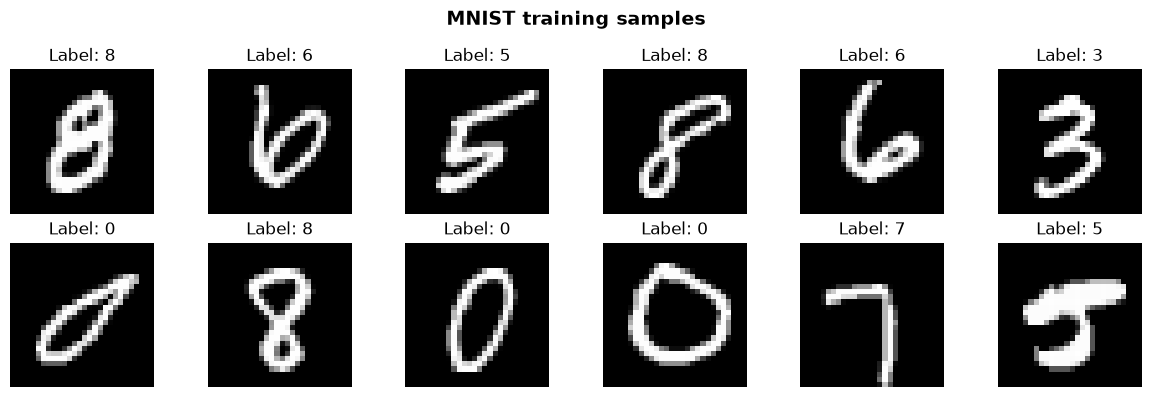

In [2]:
transform = transforms.ToTensor()
full_train_dataset = datasets.MNIST(DATA_DIR, train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(DATA_DIR, train=False, download=True, transform=transform)

train_size = int(0.8 * len(full_train_dataset))
validation_size = len(full_train_dataset) - train_size
train_dataset, validation_dataset = random_split(
    full_train_dataset, [train_size, validation_size], generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
validation_loader = DataLoader(validation_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Training images:   {len(train_dataset):,}")
print(f"Validation images: {len(validation_dataset):,}")
print(f"Test images:       {len(test_dataset):,}")

images, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 6, figsize=(12, 4))
for axis, image, label in zip(axes.ravel(), images[:12], labels[:12]):
    axis.imshow(image.squeeze(), cmap="gray")
    axis.set_title(f"Label: {label.item()}")
    axis.axis("off")
plt.suptitle("MNIST training samples", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


## 2. Define the Multi-Layer Perceptron

The MLP flattens each image into 784 features, learns two hidden representations with ReLU activations, and produces ten output logits. `CrossEntropyLoss` applies softmax internally, so the final layer has no softmax activation.


In [3]:
class MNISTMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(128, 10),
        )

    def forward(self, inputs):
        return self.network(inputs)

model = MNISTMLP().to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
print(model)
print(f"Trainable parameters: {sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad):,}")


MNISTMLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.2, inplace=False)
    (7): Linear(in_features=128, out_features=10, bias=True)
  )
)
Trainable parameters: 235,146


In [4]:
def run_epoch(data_loader, training=False):
    model.train(training)
    total_loss = 0.0
    correct_predictions = 0
    total_examples = 0

    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for batch_images, batch_labels in data_loader:
            batch_images, batch_labels = batch_images.to(DEVICE), batch_labels.to(DEVICE)
            if training:
                optimizer.zero_grad()

            logits = model(batch_images)
            loss = criterion(logits, batch_labels)

            if training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * batch_labels.size(0)
            correct_predictions += (logits.argmax(dim=1) == batch_labels).sum().item()
            total_examples += batch_labels.size(0)

    return total_loss / total_examples, correct_predictions / total_examples

history = {"train_loss": [], "validation_loss": [], "train_accuracy": [], "validation_accuracy": []}
best_validation_loss = float("inf")
epochs_without_improvement = 0
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss, train_accuracy = run_epoch(train_loader, training=True)
    validation_loss, validation_accuracy = run_epoch(validation_loader)

    history["train_loss"].append(train_loss)
    history["validation_loss"].append(validation_loss)
    history["train_accuracy"].append(train_accuracy)
    history["validation_accuracy"].append(validation_accuracy)

    print(f"Epoch {epoch:02d}/{MAX_EPOCHS} | train loss: {train_loss:.4f} | val loss: {validation_loss:.4f} | train acc: {train_accuracy:.2%} | val acc: {validation_accuracy:.2%}")

    if validation_loss < best_validation_loss:
        best_validation_loss = validation_loss
        epochs_without_improvement = 0
        torch.save(model.state_dict(), MODEL_PATH)
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print(f"Early stopping after {epoch} epochs.")
            break

model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE, weights_only=True))
print(f"Best model saved to: {MODEL_PATH}")


Epoch 01/15 | train loss: 0.4394 | val loss: 0.2036 | train acc: 87.49% | val acc: 94.01%


Epoch 02/15 | train loss: 0.1753 | val loss: 0.1391 | train acc: 94.88% | val acc: 95.82%


Epoch 03/15 | train loss: 0.1264 | val loss: 0.1153 | train acc: 96.20% | val acc: 96.58%


Epoch 04/15 | train loss: 0.0968 | val loss: 0.1006 | train acc: 97.02% | val acc: 96.98%


Epoch 05/15 | train loss: 0.0785 | val loss: 0.0922 | train acc: 97.57% | val acc: 97.26%


Epoch 06/15 | train loss: 0.0682 | val loss: 0.0898 | train acc: 97.86% | val acc: 97.30%


... (2 outputs left out)

Epoch 09/15 | train loss: 0.0466 | val loss: 0.0757 | train acc: 98.48% | val acc: 97.82%


Epoch 10/15 | train loss: 0.0413 | val loss: 0.0786 | train acc: 98.68% | val acc: 97.72%


Epoch 11/15 | train loss: 0.0352 | val loss: 0.0889 | train acc: 98.85% | val acc: 97.66%


Epoch 12/15 | train loss: 0.0322 | val loss: 0.0909 | train acc: 98.95% | val acc: 97.62%
Early stopping after 12 epochs.
Best model saved to: models\mnist_mlp.pt


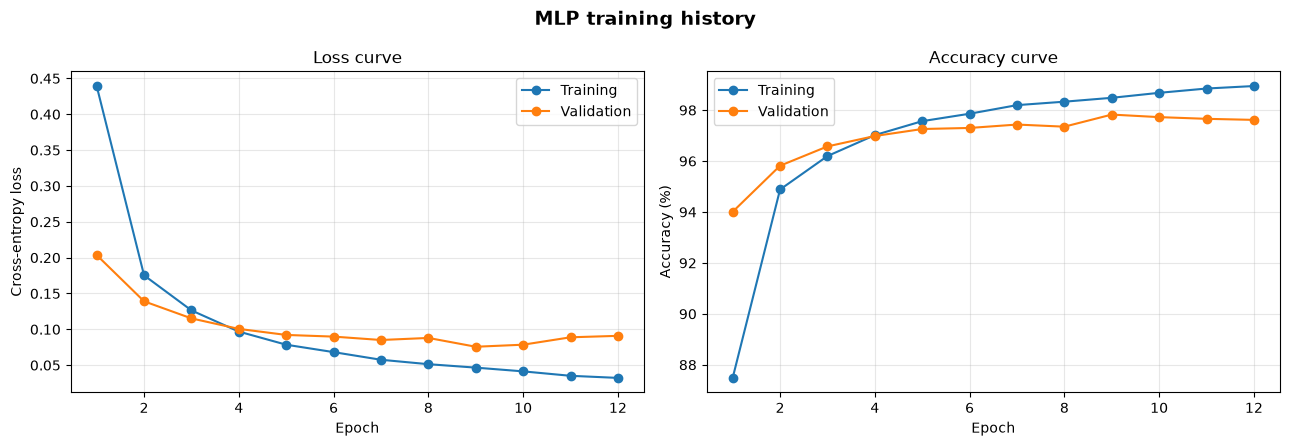

In [5]:
epochs = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(epochs, history["train_loss"], marker="o", label="Training")
axes[0].plot(epochs, history["validation_loss"], marker="o", label="Validation")
axes[0].set(title="Loss curve", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, np.array(history["train_accuracy"]) * 100, marker="o", label="Training")
axes[1].plot(epochs, np.array(history["validation_accuracy"]) * 100, marker="o", label="Validation")
axes[1].set(title="Accuracy curve", xlabel="Epoch", ylabel="Accuracy (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.suptitle("MLP training history", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


## 3. Test-set evaluation

The test set is kept untouched until training finishes. The confusion matrix shows which digits the final model most often confuses.


Final test accuracy: 97.97%


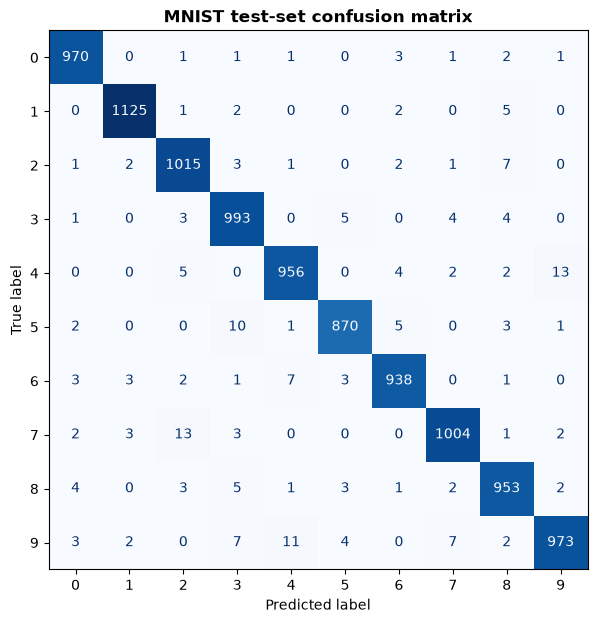

In [6]:
model.eval()
all_predictions, all_labels = [], []
with torch.no_grad():
    for batch_images, batch_labels in test_loader:
        predictions = model(batch_images.to(DEVICE)).argmax(dim=1).cpu()
        all_predictions.extend(predictions.tolist())
        all_labels.extend(batch_labels.tolist())

test_accuracy = np.mean(np.array(all_predictions) == np.array(all_labels))
print(f"Final test accuracy: {test_accuracy:.2%}")

matrix = confusion_matrix(all_labels, all_predictions)
display = ConfusionMatrixDisplay(matrix, display_labels=range(10))
fig, axis = plt.subplots(figsize=(8, 7))
display.plot(ax=axis, cmap="Blues", colorbar=False)
axis.set_title("MNIST test-set confusion matrix", fontweight="bold")
plt.show()


## 4. Data distribution and learning diagnostics

A reliable experiment begins with data inspection. The class chart verifies that no digit dominates the dataset. The generalization gap compares training and validation accuracy: a rapidly widening gap is a useful overfitting warning.


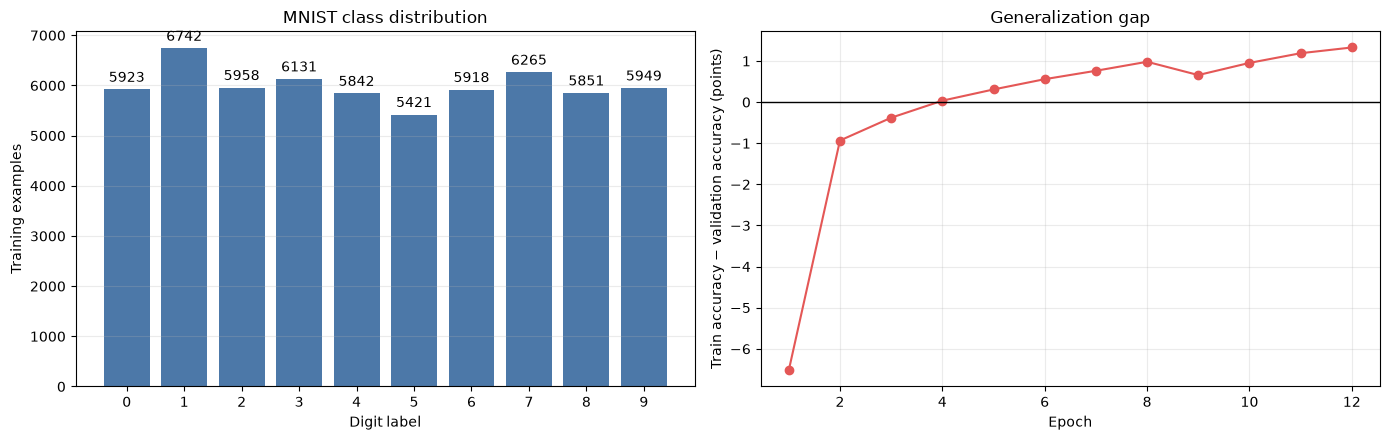

Final generalization gap: 1.33 percentage points


In [7]:
train_targets = full_train_dataset.targets.numpy()
digit_counts = np.bincount(train_targets, minlength=10)
generalization_gap = (np.array(history["train_accuracy"]) - np.array(history["validation_accuracy"])) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
bars = axes[0].bar(range(10), digit_counts, color="#4C78A8")
axes[0].bar_label(bars, padding=3, fmt="%d")
axes[0].set(title="MNIST class distribution", xlabel="Digit label", ylabel="Training examples", xticks=range(10))
axes[0].grid(axis="y", alpha=0.25)
axes[1].plot(list(epochs), generalization_gap, marker="o", color="#E45756")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set(title="Generalization gap", xlabel="Epoch", ylabel="Train accuracy − validation accuracy (points)")
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()
print(f"Final generalization gap: {generalization_gap[-1]:.2f} percentage points")


## 5. Per-class performance and prediction examples

Overall accuracy can hide weak classes. Per-class accuracy identifies the digits that are most difficult for the network. The final grid makes individual correct and incorrect predictions easy to inspect.


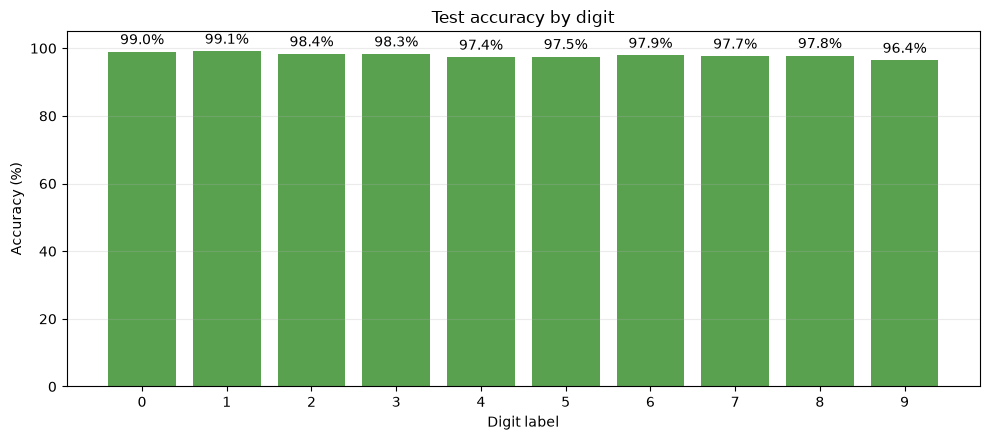

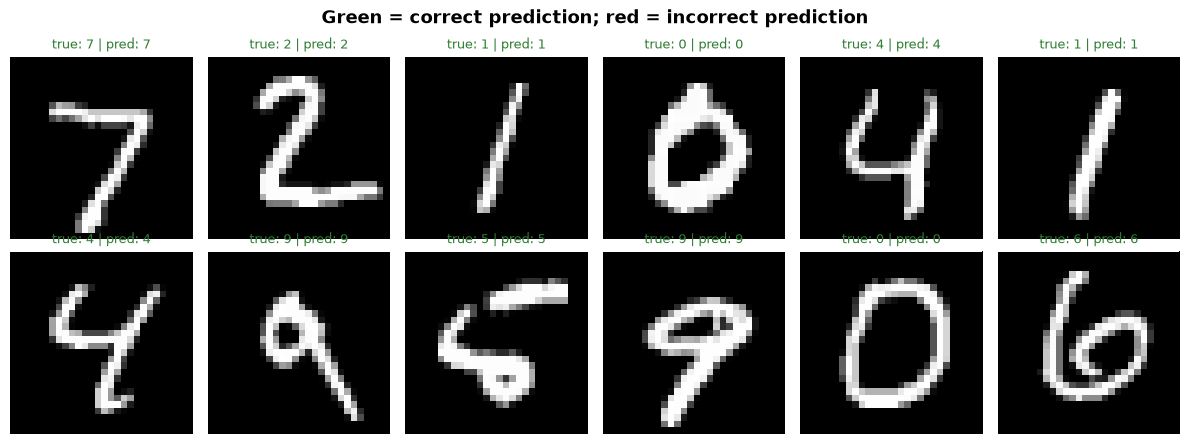

In [8]:
per_class_accuracy = np.diag(matrix) / matrix.sum(axis=1)
fig, axis = plt.subplots(figsize=(10, 4.5))
bars = axis.bar(range(10), per_class_accuracy * 100, color="#59A14F")
axis.bar_label(bars, fmt="%.1f%%", padding=3)
axis.set(title="Test accuracy by digit", xlabel="Digit label", ylabel="Accuracy (%)", xticks=range(10), ylim=(0, 105))
axis.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

example_images, example_labels = next(iter(test_loader))
with torch.no_grad():
    example_predictions = model(example_images.to(DEVICE)).argmax(dim=1).cpu()
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for axis, image, truth, prediction in zip(axes.ravel(), example_images[:12], example_labels[:12], example_predictions[:12]):
    correct = truth.item() == prediction.item()
    axis.imshow(image.squeeze(), cmap="gray")
    axis.set_title(f"true: {truth.item()} | pred: {prediction.item()}", color="#2E7D32" if correct else "#C62828", fontsize=9)
    axis.axis("off")
plt.suptitle("Green = correct prediction; red = incorrect prediction", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


## Interpretation and conclusion

- Decreasing validation loss together with rising validation accuracy indicates useful learning.
- If validation loss rises while training loss falls, stop earlier, increase dropout, or reduce model capacity.
- The saved `models/mnist_mlp.pt` file contains the best validation-loss checkpoint and can be loaded for inference without retraining.
